<a href="https://colab.research.google.com/github/jahnavireddy-27/Digital-Image-Processing-Image-Enhancement-and-Noise-Reduction/blob/master/dip_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Low Contrast Image**

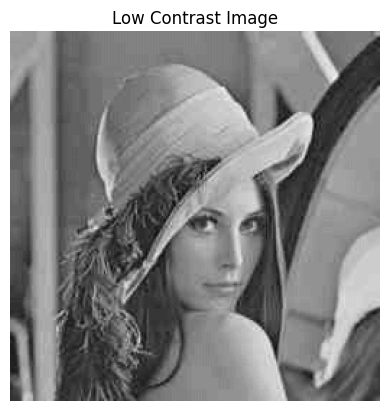

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def display_image(image, title):
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis("off")
    plt.show()

image = cv2.imread("LC_pic4.jpg", cv2.IMREAD_GRAYSCALE)
low_contrast_image = cv2.normalize(image, None, alpha=80, beta=150, norm_type=cv2.NORM_MINMAX) # Reduce contrast using normalization
cv2.imwrite("LC_pic4.jpg", low_contrast_image)
display_image(low_contrast_image, "Low Contrast Image")


# **Adding Salt and Pepper Noise**

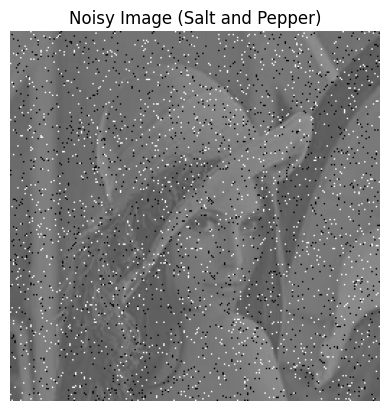

In [ ]:
def add_salt_and_pepper_noise(image, amount=0.05):
    noisy_image = image.copy()
    num_salt = int(amount * image.size * 0.5)
    num_pepper = int(amount * image.size * 0.5)

    coords = [np.random.randint(0, i, num_salt) for i in image.shape]   #salt (white pixels)
    noisy_image[coords[0], coords[1]] = 255

    coords = [np.random.randint(0, i, num_pepper) for i in image.shape]   # pepper (black pixels)
    noisy_image[coords[0], coords[1]] = 0
    return noisy_image


noisy_image = add_salt_and_pepper_noise(low_contrast_image, amount=0.05)
cv2.imwrite("noisy_image.jpg", noisy_image)
display_image(noisy_image, "Noisy Image (Salt and Pepper)")


# **Mean Filters**

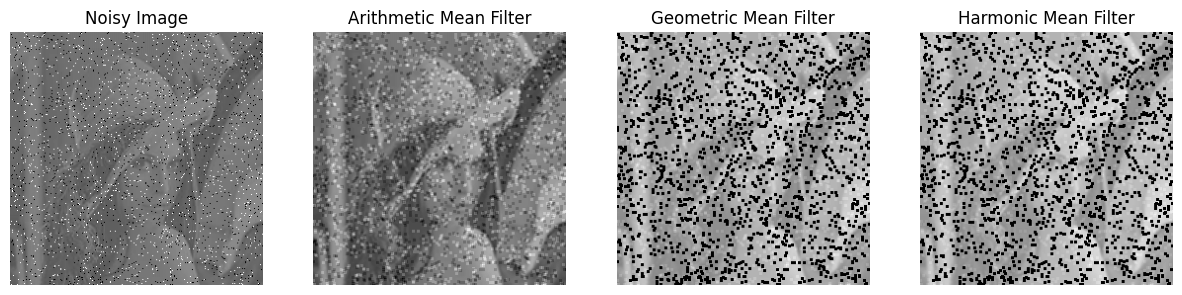

In [ ]:
def arithmetic_mean_filter(image, ksize=3):
    kernel = np.ones((ksize, ksize), dtype=np.float32) / (ksize * ksize)
    return cv2.filter2D(image, -1, kernel)

def geometric_mean_filter(image, ksize=3):
    padded_image = np.pad(image, pad_width=ksize//2, mode='reflect')
    output_image = np.zeros_like(image, dtype=np.float32)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            neighborhood = padded_image[i:i+ksize, j:j+ksize]
            output_image[i, j] = np.prod(neighborhood**(1 / (ksize * ksize)))
    return np.clip(output_image, 0, 255).astype(np.uint8)

def harmonic_mean_filter(image, ksize=3):
    padded_image = np.pad(image, pad_width=ksize//2, mode='reflect')
    output_image = np.zeros_like(image, dtype=np.float32)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            neighborhood = padded_image[i:i+ksize, j:j+ksize]
            output_image[i, j] = (ksize * ksize) / np.sum(1.0 / (neighborhood + 1e-5))
    return np.clip(output_image, 0, 255).astype(np.uint8)

# Applying mean filters
arithmetic_mean = arithmetic_mean_filter(noisy_image)
geometric_mean = geometric_mean_filter(noisy_image)
harmonic_mean = harmonic_mean_filter(noisy_image)

def display_images(images, titles, rows, cols):
    plt.figure(figsize=(15, 5))
    for i in range(len(images)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(images[i], cmap='gray')
        plt.title(titles[i])
        plt.axis('off')
    plt.show()

images = [noisy_image, arithmetic_mean, geometric_mean, harmonic_mean]
titles = [
    "Noisy Image", "Arithmetic Mean Filter",
    "Geometric Mean Filter", "Harmonic Mean Filter"
]

display_images(images, titles, rows=1, cols=4)

# **Order Statistics Filters**

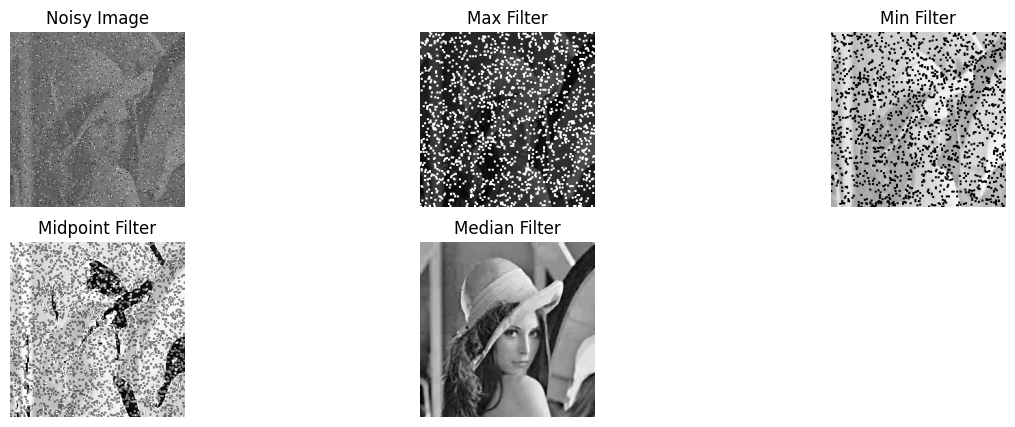

In [ ]:
def max_filter(image, ksize=3):
    return cv2.dilate(image, np.ones((ksize, ksize), np.uint8))

def min_filter(image, ksize=3):
    return cv2.erode(image, np.ones((ksize, ksize), np.uint8))

def midpoint_filter(image, ksize=3):
    max_img = max_filter(image, ksize)
    min_img = min_filter(image, ksize)
    return ((max_img + min_img) / 2).astype(np.uint8)

def median_filter(image, ksize=3):
    return cv2.medianBlur(image, ksize)

# Applying order statistics filters
max_filtered = max_filter(noisy_image)
min_filtered = min_filter(noisy_image)
midpoint_filtered = midpoint_filter(noisy_image)
median_filtered = median_filter(noisy_image)


images = [noisy_image, max_filtered, min_filtered, midpoint_filtered, median_filtered]
titles = [
    "Noisy Image", "Max Filter", "Min Filter",
    "Midpoint Filter", "Median Filter"
]

display_images(images, titles, rows=2, cols=3)


# **Adaptive Filters**

<ipython-input-6-0791e3a9c1c8>:4: RuntimeWarning: divide by zero encountered in divide
  output = mean + ((variance - noise_variance) / variance) * (image - mean)
<ipython-input-6-0791e3a9c1c8>:4: RuntimeWarning: invalid value encountered in multiply
  output = mean + ((variance - noise_variance) / variance) * (image - mean)
<ipython-input-6-0791e3a9c1c8>:5: RuntimeWarning: invalid value encountered in cast
  return np.clip(output, 0, 255).astype(np.uint8)


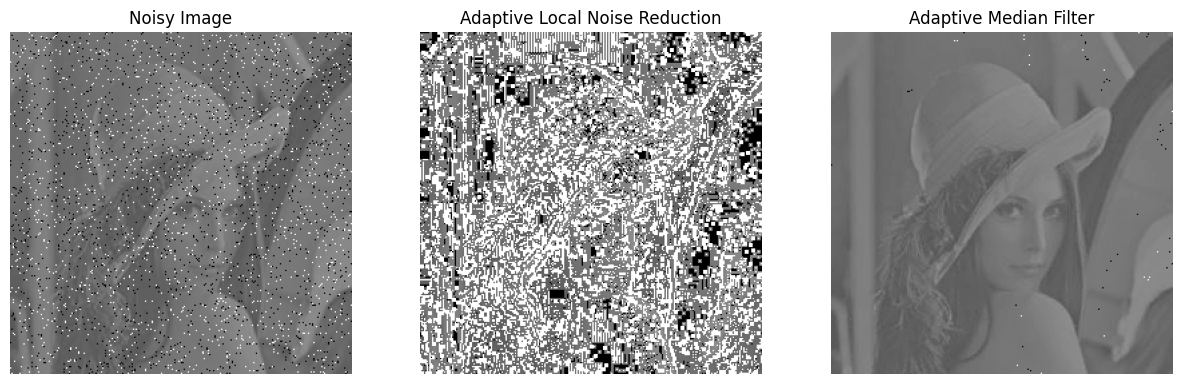

In [ ]:
def adaptive_local_noise_reduction(image, noise_variance=0.01):
    mean = cv2.blur(image, (3, 3))
    variance = cv2.blur(image ** 2, (3, 3)) - mean ** 2
    output = mean + ((variance - noise_variance) / variance) * (image - mean)
    return np.clip(output, 0, 255).astype(np.uint8)

def adaptive_median_filter(image, max_ksize=7):
    padded_image = np.pad(image, pad_width=max_ksize//2, mode='reflect')
    output_image = np.copy(image)
    for ksize in range(3, max_ksize + 1, 2):
        for i in range(image.shape[0]):
            for j in range(image.shape[1]):
                neighborhood = padded_image[i:i+ksize, j:j+ksize]
                z_min, z_max = neighborhood.min(), neighborhood.max()
                z_med = np.median(neighborhood)
                z_xy = image[i, j]
                if z_min < z_med < z_max:
                    if z_min < z_xy < z_max:
                        output_image[i, j] = z_xy
                    else:
                        output_image[i, j] = z_med
                else:
                    continue
    return output_image

# Applying both adaptive filters
adaptive_noise_reduction = adaptive_local_noise_reduction(noisy_image)
adaptive_median = adaptive_median_filter(noisy_image)

images = [noisy_image, adaptive_noise_reduction, adaptive_median]
titles = ["Noisy Image", "Adaptive Local Noise Reduction", "Adaptive Median Filter"]

display_images(images, titles, rows=1, cols=3)


# **Frequncy Domain Filters**

**Ideal Bandreject, Bandpass, Notch Filters**

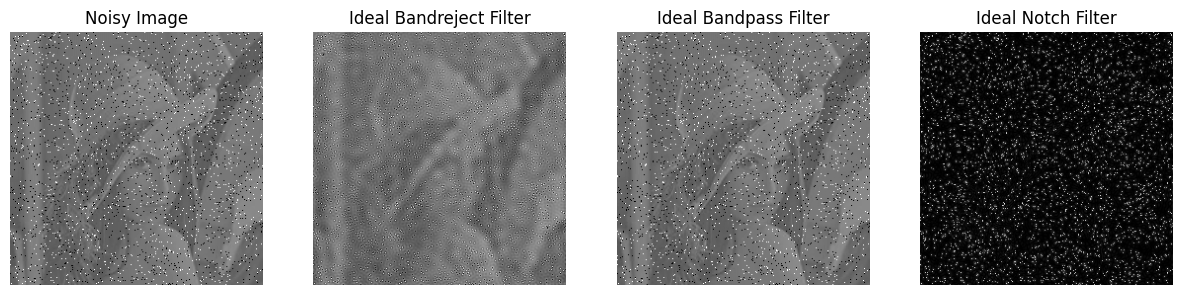

In [ ]:
def ideal_filter(image, filter_type="bandreject", cutoff=30, radius=20):
    # Convert image to frequency domain (Fourier Transform)
    f_image = np.fft.fft2(image)
    fshift = np.fft.fftshift(f_image)
    rows, cols = image.shape
    center = (rows // 2, cols // 2)

    # Create mask
    mask = np.ones((rows, cols), dtype=np.uint8)
    for i in range(rows):
        for j in range(cols):
            distance = np.sqrt((i - center[0])**2 + (j - center[1])**2)
            if filter_type == "bandreject" and radius - cutoff < distance < radius + cutoff:
                mask[i, j] = 0
            elif filter_type == "bandpass" and (distance > radius - cutoff and distance < radius + cutoff):
                mask[i, j] = 1
            elif filter_type == "notch" and distance < cutoff:
                mask[i, j] = 0

    # Apply mask and inverse FFT
    fshift = fshift * mask
    f_ishift = np.fft.ifftshift(fshift)
    img_back = np.abs(np.fft.ifft2(f_ishift))
    return np.uint8(img_back)

ideal_bandreject = ideal_filter(noisy_image, filter_type="bandreject", cutoff=30, radius=50)
ideal_bandpass = ideal_filter(noisy_image, filter_type="bandpass", cutoff=30, radius=50)
ideal_notch = ideal_filter(noisy_image, filter_type="notch", cutoff=50)

images = [noisy_image, ideal_bandreject, ideal_bandpass, ideal_notch]
titles = [
    "Noisy Image", "Ideal Bandreject Filter",
    "Ideal Bandpass Filter", "Ideal Notch Filter"
]

display_images(images, titles, rows=1, cols=4)


**Butterworth Bandreject, Bandpass, Notch Filters**

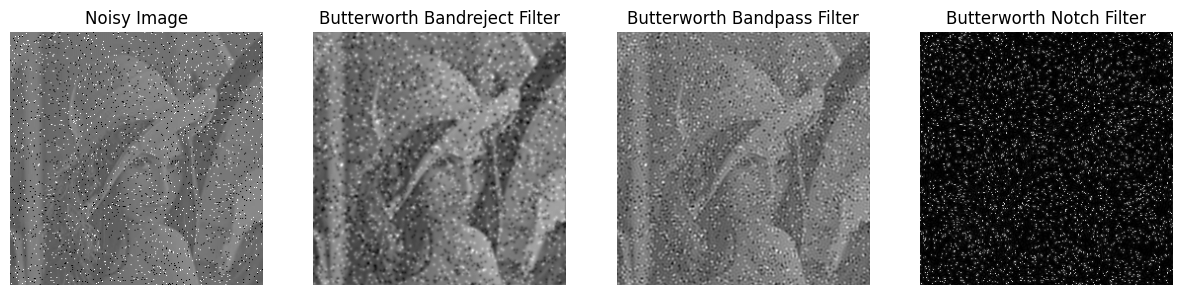

In [ ]:
def butterworth_filter(image, filter_type="bandreject", cutoff=30, radius=20, order=2):
    # Convert image to frequency domain (Fourier Transform)
    f_image = np.fft.fft2(image)
    fshift = np.fft.fftshift(f_image)
    rows, cols = image.shape
    center = (rows // 2, cols // 2)

    # Create Butterworth filter mask
    mask = np.ones((rows, cols), dtype=np.float32)
    for i in range(rows):
        for j in range(cols):
            distance = np.sqrt((i - center[0])**2 + (j - center[1])**2)
            if filter_type == "bandreject":
                D = np.sqrt((i - center[0])**2 + (j - center[1])**2)
                mask[i, j] = 1 / (1 + (D / radius)**(2 * order))
                if D > radius + cutoff and D < radius - cutoff:
                    mask[i, j] = 0
            elif filter_type == "bandpass":
                D = np.sqrt((i - center[0])**2 + (j - center[1])**2)
                mask[i, j] = (1 + (D / radius)**(2 * order))**(-1)
                if D > radius - cutoff and D < radius + cutoff:
                    mask[i, j] = 1
            elif filter_type == "notch":
                D = np.sqrt((i - center[0])**2 + (j - center[1])**2)
                if D < cutoff:
                    mask[i, j] = 0

    # Apply mask and inverse FFT
    fshift = fshift * mask
    f_ishift = np.fft.ifftshift(fshift)
    img_back = np.abs(np.fft.ifft2(f_ishift))
    return np.uint8(img_back)


butterworth_bandreject = butterworth_filter(noisy_image, filter_type="bandreject", cutoff=30, radius=50, order=2)
butterworth_bandpass = butterworth_filter(noisy_image, filter_type="bandpass", cutoff=30, radius=50, order=2)
butterworth_notch = butterworth_filter(noisy_image, filter_type="notch", cutoff=50, radius=50, order=2)

images = [noisy_image, butterworth_bandreject, butterworth_bandpass, butterworth_notch]
titles = [
    "Noisy Image", "Butterworth Bandreject Filter",
    "Butterworth Bandpass Filter", "Butterworth Notch Filter"
]

display_images(images, titles, rows=1, cols=4)


**Gaussian Bandreject, Bandpass, Notch Filters**

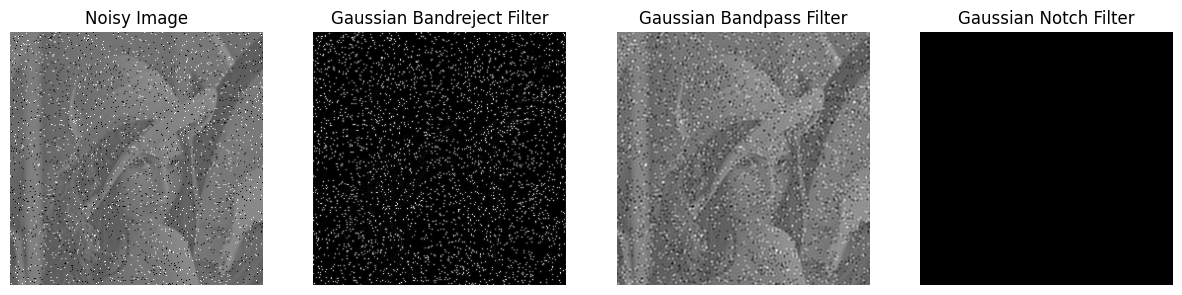

In [ ]:
def gaussian_filter(image, filter_type="bandreject", cutoff=30, radius=20, sigma=20):
    # Convert image to frequency domain (Fourier Transform)
    f_image = np.fft.fft2(image)
    fshift = np.fft.fftshift(f_image)
    rows, cols = image.shape
    center = (rows // 2, cols // 2)

    # Create Gaussian filter mask
    mask = np.ones((rows, cols), dtype=np.float32)
    for i in range(rows):
        for j in range(cols):
            D = np.sqrt((i - center[0])**2 + (j - center[1])**2)
            if filter_type == "bandreject":
                mask[i, j] = 1 - np.exp(-(D**2) / (2 * (radius**2)))
                if D > radius + cutoff and D < radius - cutoff:
                    mask[i, j] = 0
            elif filter_type == "bandpass":
                mask[i, j] = np.exp(-(D**2) / (2 * (radius**2)))
                if D > radius - cutoff and D < radius + cutoff:
                    mask[i, j] = 1
            elif filter_type == "notch":
                mask[i, j] = np.exp(-(D**2) / (2 * (sigma**2)))
                if D < cutoff:
                    mask[i, j] = 0

    # Apply mask and inverse FFT
    fshift = fshift * mask
    f_ishift = np.fft.ifftshift(fshift)
    img_back = np.abs(np.fft.ifft2(f_ishift))
    return np.uint8(img_back)

gaussian_bandreject = gaussian_filter(noisy_image, filter_type="bandreject", cutoff=30, radius=50, sigma=20)
gaussian_bandpass = gaussian_filter(noisy_image, filter_type="bandpass", cutoff=30, radius=50, sigma=20)
gaussian_notch = gaussian_filter(noisy_image, filter_type="notch", cutoff=50, radius=50, sigma=20)

images = [noisy_image, gaussian_bandreject, gaussian_bandpass, gaussian_notch]
titles = [
    "Noisy Image", "Gaussian Bandreject Filter",
    "Gaussian Bandpass Filter", "Gaussian Notch Filter"
]

display_images(images, titles, rows=1, cols=4)


**Frequency Domain Filters** don’t perform well for salt-and-pepper noise because this noise is impulsive and localized. These filters work better for continuous noise like Gaussian noise, as they rely on frequency components which are not suited for sharp, isolated pixel disturbances like salt-and-pepper noise.


 **Spatial Domain Filters** are more effective for salt-and-pepper noise because they operate directly on pixel values, using local information to replace noisy pixels. Among them, the **Median Filter** performs the best as it effectively removes outliers (salt-and-pepper noise) without blurring the image, preserving edges and fine details.


### **Contrast Stretching:**

The pixel values are normalized based on the minimum and maximum values of the image, then stretched to the full range of 0 to 255.

### **Histogram Equalization:**

cv2.equalizeHist() adjusts the intensity distribution, making the pixel intensities more evenly spread across the range of 0 to 255. This improves the contrast in images with poor lighting or low contrast.


In [ ]:
def contrast_stretching(image):
    min_val = np.min(image)
    max_val = np.max(image)
    stretched_image = ((image - min_val) / (max_val - min_val)) * 255
    return stretched_image.astype(np.uint8)

# 2. Histogram Equalization
def histogram_equalization(image):
    return cv2.equalizeHist(image)

# Applying Contrast Stretching
stretched_image = contrast_stretching(median_filtered )

# Applying Histogram Equalization
equalized_image = histogram_equalization(median_filtered )


images = [median_filtered , stretched_image, equalized_image]
titles = ['Original Image', 'Contrast Stretching', 'Histogram Equalization']

plt.figure(figsize=(10, 5))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.show()

Both methods will improve the contrast, but **Histogram Equalization** typically works better for images with varying lighting or low contrast overall. Contrast Stretching is simpler and may be more suitable for images with a well-defined contrast range.